# ICU Patient Similarity Search and RAG with Llama 3.1

**Dataset:** MIMIC-III ICU admissions (`mimic3c.csv`, aggregated version from Kaggle)
**Related project:** [ICU Mortality Risk Prediction](https://github.com/KrishnaKJoshi1/icu-mortality-risk-prediction)
**Tools:** Sentence Transformers · FAISS · Llama 3.1 8B (Ollama) · pandas · scikit-learn

## Overview

My ICU mortality prediction project answers: *"How likely is this patient to die?"*

This notebook answers a different question: *"Which past patients looked like this one, and what happened to them?"*

It is a **retrospective** analysis of completed admissions, not a real-time decision-support tool: some of the information used (daily care activity) is only known once the stay is over.

How it works:
1. Each admission is written as a short text summary, built from its own columns.
2. A sentence-embedding model turns each summary into a list of numbers (a vector).
3. FAISS searches these vectors to find the most similar past patients.
4. Llama 3.1 writes a short comparison of those patients.
5. Python checks whether the search and the LLM answers are actually correct.

```
mimic3c.csv ─► adults ─► 5,000 patients ─► library (4,000) + new patients (1,000)
                                │
                                ▼
                   each row ─► short text summary
                                │
                                ▼
            Sentence Transformer ─► 384 numbers per patient
                                │
                                ▼
                 FAISS ─► 10 most similar library patients
                                │
                ┌───────────────┴───────────────┐
                ▼                               ▼
     Is the search good?               Llama 3.1 (Ollama)
  compare with 2 simple methods      writes a comparison
                                                │
                                                ▼
                                   Python checks the answer
```

**Data handling:** the embedding model and Llama 3.1 both run on the laptop, so no patient record is sent to an online service. Patient-level data files are not included in this repository, in line with the MIMIC data use agreement.

## 1. Setup

Libraries and project settings.


In [1]:
# Hide non-critical library warnings
import os
import warnings
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")

In [2]:
import time
import re
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score

from sentence_transformers import SentenceTransformer
import faiss
import ollama

pd.set_option("display.max_colwidth", 120)

In [37]:
# Settings
RANDOM_STATE = 42
SAMPLE_SIZE = 5000        # patients used in this notebook
NEW_PATIENT_SHARE = 0.20  # 20% become "new" patients, 80% the library
K_EVAL = 10               # similar patients used for evaluation
K_RAG = 5                 # similar patients given to the LLM
N_RAG_PATIENTS = 10       # new patients sent to the LLM

EMBEDDING_MODEL = "all-MiniLM-L6-v2"
LLM_MODEL = "llama3.1:8b"

# Data file: in this folder or one folder up
DATA_PATH = Path("mimic3c.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../mimic3c.csv")

# Folders for saved results
Path("outputs").mkdir(exist_ok=True)
Path("images").mkdir(exist_ok=True)
RAG_FILE = Path("outputs/rag_explanations.csv")

## 2. Cohort Definition

Only adults are kept. Newborn admissions (age 0) have very different diagnoses and almost never die, so they would form a separate group and confuse the search. Admissions without a diagnosis are also removed.

Each step is recorded to show how many patients remain.

In [4]:
df = pd.read_csv(DATA_PATH)
steps = [("All admissions", len(df))]

# Keep adults only
df = df[df["age"] >= 18]
steps.append(("Age 18 or older", len(df)))

# Keep admissions that have a diagnosis
df = df[df["AdmitDiagnosis"].notna()]
steps.append(("Diagnosis recorded", len(df)))

pd.DataFrame(steps, columns=["Step", "Admissions"])

,Step,Admissions
0,All admissions,58976
1,Age 18 or older,50765
2,Diagnosis recorded,50740


In [5]:
print("Patients:", len(df))
print("Died in hospital:", round(df["ExpiredHospital"].mean() * 100, 1), "%")
print("Different diagnosis phrases:", df["AdmitDiagnosis"].nunique())

Patients: 50740
Died in hospital: 11.4 %
Different diagnosis phrases: 15602


### Observation
- **50,740 adult admissions** remain out of 58,976.
- **11.4%** died in hospital. This is higher than the 9.9% in the full data, because newborns, who almost never die, were removed.
- There are **15,602 different diagnosis phrases**. This free text is too varied to turn into normal columns, which is why the patients are written as text and compared with embeddings.

## 3. Reference Library and Query Patients

A random 5,000 patients keeps the notebook fast on a laptop. They are split into two groups:

- **Library (80%):** past patients stored in the search index
- **New patients (20%):** patients we search for

A new patient is never in the library, so it cannot find itself. This is the same idea as a train/test split. The split keeps the same death rate in both groups (`stratify`).

In [6]:
sample = df.sample(SAMPLE_SIZE, random_state=RANDOM_STATE)

library, new_patients = train_test_split(
    sample,
    test_size=NEW_PATIENT_SHARE,
    random_state=RANDOM_STATE,
    stratify=sample["ExpiredHospital"],
)

# Number the rows 0, 1, 2 ... so row numbers match positions in the search index
library = library.reset_index(drop=True)
new_patients = new_patients.reset_index(drop=True)

print("Library:", len(library), "| died", round(library["ExpiredHospital"].mean() * 100, 1), "%")
print("New patients:", len(new_patients), "| died", round(new_patients["ExpiredHospital"].mean() * 100, 1), "%")

Library: 4000 | died 11.4 %
New patients: 1000 | died 11.4 %


### Observation
- 4,000 library patients and 1,000 new patients, both with 11.4% deaths.
- This copies a real situation: a hospital keeps past cases and looks up the closest ones when a new patient arrives.

## 4. Patient Summary Generation

Embedding models work on sentences, so each row is written as a short sentence-style summary.

**Activity counts become categories.** Text embeddings may not preserve exact numerical differences reliably. Daily counts (labs, medications and so on) are therefore written as *low*, *medium* or *high*. The limits are the bottom third and top third of the **library only**, so new patients do not affect them.

**Some columns are left out on purpose:**

| Left out | Why |
|---|---|
| `ExpiredHospital` (died) | Used later to test the search |
| `LOSdays`, `LOSgroupNum` (length of stay) | Also used to test the search |
| `insurance`, `religion`, `ethnicity`, `marital_status` | Similar patients should be similar medically, not socially |
| `hadm_id` | Just an ID |

In [7]:
# Activity columns and the words used for them in the summary
ACTIVITY_COLS = {
    "NumLabs": "lab tests",
    "NumRx": "medications",
    "NumMicroLabs": "microbiology tests",
    "NumProcs": "procedures",
    "NumChartEvents": "charted observations",
}

# Low / medium / high limits, taken from the library only
cutoffs = {}
for col in ACTIVITY_COLS:
    cutoffs[col] = library[col].quantile([1/3, 2/3]).tolist()

pd.DataFrame(cutoffs, index=["low up to", "medium up to"]).round(2)

,NumLabs,NumRx,NumMicroLabs,NumProcs,NumChartEvents
low up to,34.72,7.28,0.31,0.28,288.34
medium up to,47.50,11.50,1.13,0.62,605.54


In [8]:
def activity_level(value, col):
    # Turn a daily count into "low", "medium" or "high"
    low_limit, high_limit = cutoffs[col]
    if value <= low_limit:
        return "low"
    elif value <= high_limit:
        return "medium"
    else:
        return "high"


# Plain words for where the patient came from
LOCATION_WORDS = {
    "EMERGENCY ROOM ADMIT": "from the emergency room",
    "PHYS REFERRAL/NORMAL DELI": "by physician referral",
    "CLINIC REFERRAL/PREMATURE": "by clinic referral",
    "TRANSFER FROM HOSP/EXTRAM": "as a transfer from another hospital",
    "TRANSFER FROM SKILLED NUR": "as a transfer from a skilled nursing facility",
}

In [9]:
def make_summary(row):
    # Write one patient (one row) as a short text summary
    gender = "female" if row["gender"] == "F" else "male"
    location = LOCATION_WORDS.get(row["admit_location"], "from another source")

    procedure = str(row["AdmitProcedure"]).lower()
    if procedure == "na":
        procedure = "none recorded"

    activity = []
    for col, words in ACTIVITY_COLS.items():
        activity.append(activity_level(row[col], col) + " " + words)

    summary = (
        f"{row['age']}-year-old {gender}. "
        f"{row['admit_type'].lower().capitalize()} admission {location}. "
        f"Admitting diagnosis: {row['AdmitDiagnosis'].lower()}. "
        f"First recorded procedure: {procedure}. "
        f"Daily care activity: {', '.join(activity)}."
    )
    return summary


library["summary"] = library.apply(make_summary, axis=1)
new_patients["summary"] = new_patients.apply(make_summary, axis=1)

# Show three examples
for text in library["summary"].head(3):
    print(text, "\n")

54-year-old male. Emergency admission from the emergency room. Admitting diagnosis: fever. First recorded procedure: insert vasc access dev. Daily care activity: high lab tests, high medications, high microbiology tests, high procedures, medium charted observations. 

81-year-old female. Emergency admission from the emergency room. Admitting diagnosis: sepsis. First recorded procedure: ven cath renal dialysis. Daily care activity: medium lab tests, low medications, high microbiology tests, medium procedures, medium charted observations. 

80-year-old male. Emergency admission by clinic referral. Admitting diagnosis: +ett\cath. First recorded procedure: 1 int mam-cor art bypass. Daily care activity: medium lab tests, medium medications, low microbiology tests, medium procedures, low charted observations. 



In [10]:
word_counts = library["summary"].str.split().str.len()
print("Words per summary: median", int(word_counts.median()), "| max", word_counts.max())

Words per summary: median 35 | max 51


### Observation
- Every patient now has one readable summary of about 35 words (maximum 51). That is short enough for the embedding model, which reads up to about 256 word pieces.
- The summary describes the patient medically (age, sex, how they arrived, diagnosis, first procedure, how intensive the care was) and says nothing about whether they died.
- `AdmitProcedure` is the first procedure recorded during the stay, not always one done on arrival, so it is called "first recorded procedure".
- The activity counts cover the whole hospital stay. They show how intensive the care was, but they are **not** known at the moment of admission.

## 5. Text Embeddings

`all-MiniLM-L6-v2` is a small, free and widely used sentence-embedding model (about 90 MB). It turns each summary into a list of **384 numbers**. Summaries with a similar meaning get similar numbers, even if the words are not exactly the same.

The model downloads once and then runs on the laptop. No patient data is uploaded.

`normalize_embeddings=True` gives every vector the same length (1). This makes it easy to measure how similar two vectors are; the measure is called **cosine similarity** (1 = same meaning, 0 = unrelated).

In [11]:
embedding_model = SentenceTransformer(EMBEDDING_MODEL)

start = time.time()

library_vectors = embedding_model.encode(
    library["summary"].tolist(),
    batch_size=64,
    normalize_embeddings=True,
    show_progress_bar=True,
)
new_vectors = embedding_model.encode(
    new_patients["summary"].tolist(),
    batch_size=64,
    normalize_embeddings=True,
    show_progress_bar=True,
)

print("Library vectors:", library_vectors.shape)
print("New-patient vectors:", new_vectors.shape)
print("Time:", round(time.time() - start), "seconds")

Batches: 100%|██████████| 16/16 [00:25<00:00,  1.57s/it]

Library vectors: (4000, 384)
New-patient vectors: (1000, 384)
Time: 118 seconds


### Observation
- Each admission is now represented by a vector of 384 numbers: 4,000 for the library and 1,000 for the query patients.
- This took about 3 minutes on a laptop. All 50,740 adults would take about 30 minutes, but this is done only once; searching afterwards is almost instant.

## 6. FAISS Index and Search

FAISS does not create the vectors. It stores them and quickly finds the ones closest to a query.

`IndexFlatIP` compares a new patient with every library patient. Because all vectors have length 1, this comparison is the cosine similarity. With 4,000 patients this exact search takes a fraction of a second. Faster, approximate indexes are only needed for millions of records.

In [12]:
dimension = library_vectors.shape[1]          # 384 numbers per patient

index = faiss.IndexFlatIP(dimension)           # exact search using cosine similarity
index.add(library_vectors.astype("float32"))   # FAISS needs float32 numbers

print("Patients in the index:", index.ntotal)

Patients in the index: 4000


In [13]:
# For every new patient, find the 10 most similar library patients
start = time.time()
scores, neighbor_ids = index.search(new_vectors.astype("float32"), K_EVAL)
print("Searched", len(new_vectors), "patients in", round(time.time() - start, 3), "seconds")

# scores[i]       = similarity of the 10 matches for new patient i (best first)
# neighbor_ids[i] = row numbers of those 10 matches in the library
print("Result shape:", neighbor_ids.shape)

Searched 1000 patients in 0.158 seconds
Result shape: (1000, 10)


## 7. Example Retrievals

A new patient and its five closest library patients. Outcome and length of stay are shown only to judge the result; they were not in the summaries.

In [14]:
def show_matches(patient_row, k=5):
    # Print one new patient and a table of its k closest library patients
    patient = new_patients.iloc[patient_row]
    print("NEW PATIENT:", patient["summary"])
    print("Outcome:", "died" if patient["ExpiredHospital"] == 1 else "survived",
          "| Length of stay:", round(patient["LOSdays"], 1), "days\n")

    rows = []
    for rank in range(k):
        match = library.iloc[neighbor_ids[patient_row, rank]]
        rows.append({
            "rank": rank + 1,
            "similarity": round(float(scores[patient_row, rank]), 3),
            "age": match["age"],
            "admitting diagnosis": match["AdmitDiagnosis"],
            "outcome": "died" if match["ExpiredHospital"] == 1 else "survived",
            "LOS days": round(match["LOSdays"], 1),
        })
    return pd.DataFrame(rows)


# Example 1: the first new patient who survived
first_survivor = new_patients.index[new_patients["ExpiredHospital"] == 0][0]
show_matches(first_survivor)

NEW PATIENT: 71-year-old female. Emergency admission from the emergency room. Admitting diagnosis: pneumonia. First recorded procedure: none recorded. Daily care activity: medium lab tests, medium medications, medium microbiology tests, low procedures, low charted observations.
Outcome: survived | Length of stay: 12.8 days



,rank,similarity,age,admitting diagnosis,outcome,LOS days
0,1,0.986,77,PNEUMONIA,survived,5.0
1,2,0.982,77,PNEUMONIA,survived,12.0
2,3,0.980,70,PNEUMONIA,survived,3.8
3,4,0.979,69,PNEUMONIA,survived,7.2
4,5,0.975,82,PNEUMONIA,survived,4.1


In [15]:
# Example 2: the first new patient who died
first_death = new_patients.index[new_patients["ExpiredHospital"] == 1][0]
show_matches(first_death)

NEW PATIENT: 75-year-old male. Emergency admission as a transfer from another hospital. Admitting diagnosis: endocarditis. First recorded procedure: dx ultrasound-heart. Daily care activity: high lab tests, high medications, high microbiology tests, high procedures, high charted observations.
Outcome: died | Length of stay: 5.0 days



,rank,similarity,age,admitting diagnosis,outcome,LOS days
0,1,0.827,62,ENDOCARDITIS,survived,23.8
1,2,0.808,79,ENDOCARDITIS,survived,19.8
2,3,0.796,53,ENDOCARDITIS,died,10.9
3,4,0.781,35,STROKE;TELEMETRY;TRANSIENT ISCHEMIC ATTACK,survived,6.4
4,5,0.781,31,ENDOCARDITIS,survived,8.6


### Observation
- **Example 1 (pneumonia, survived):** all five matches have pneumonia, are of a similar age (69–82) and survived. Similarity is very high (about 0.98). For common diagnoses, the search finds close and sensible matches.
- **Example 2 (endocarditis, died):** four of the five matches have the same, fairly rare diagnosis, and one of them died. Similarity is lower (0.78–0.83), because few library patients look like this one.
- The fourth match in Example 2 (stroke) was found because it shares the same first procedure, *dx ultrasound-heart*. The search matches **words**, not medical reasoning.
- Ages in Example 2 range from 31 to 79 for a 75-year-old. The model sees the age only as a number in the text and gives it little weight.

## 8. Retrieval Evaluation Against Two Baselines

There is no answer key for "similar patients". So the search is judged with information that was **not** in the summaries, plus diagnosis and age as basic checks:

| Measure | Question |
|---|---|
| Same diagnosis % | How many of the 10 matches have exactly the same diagnosis? |
| Age gap | On average, how many years apart are the patient and its matches? |
| LOS correlation | Do patients with long stays get matches with long stays? (Spearman, −1 to 1) |
| Match death rate | Share of the 10 matches who died, for patients who died vs survived |
| Match death-rate AUC | If the matches' death rate were used as a risk score, how well would it separate deaths from survivors? (0.5 = coin flip, 1 = perfect) |

Two simple methods are measured the same way:
- **Random:** 10 random library patients. Any useful method must beat this.
- **Numeric k-NN:** the classic method without text. It finds the nearest patients using scaled numbers (age, sex, admission type and source, activity counts). It cannot use the diagnosis text.

Note: this compares two ways of **representing** a patient (text embeddings vs scaled numbers), not two search tools. FAISS and k-NN both simply return the nearest neighbours.

**Step 1 – Describe each new patient's 10 matches.** For every new patient, look up its matches and record: share with the same diagnosis, average age difference, share who died, and their average length of stay.

In [16]:
# Upper-case diagnosis, so "Sepsis" and "SEPSIS" count as the same
library["dx"] = library["AdmitDiagnosis"].str.upper().str.strip()
new_patients["dx"] = new_patients["AdmitDiagnosis"].str.upper().str.strip()


def match_table(ids):
    # One row per new patient, describing its 10 matches
    rows = []
    for i in range(len(new_patients)):
        patient = new_patients.iloc[i]
        matches = library.iloc[ids[i]]
        rows.append({
            "died": patient["ExpiredHospital"],
            "los": patient["LOSdays"],
            "same_dx_share": (matches["dx"] == patient["dx"]).mean(),
            "age_gap": (matches["age"] - patient["age"]).abs().mean(),
            "match_death_rate": matches["ExpiredHospital"].mean(),
            "match_los": matches["LOSdays"].mean(),
        })
    return pd.DataFrame(rows)

**Step 2 – Turn the table into one row of results per method.** Averages of the table above, plus the Spearman correlation and the AUC.

In [17]:
def score_method(ids, method_name):
    # Turn the match table into one row of results
    table = match_table(ids)
    died = table[table["died"] == 1]
    survived = table[table["died"] == 0]
    return {
        "method": method_name,
        "same diagnosis %": round(table["same_dx_share"].mean() * 100, 1),
        "age gap (years)": round(table["age_gap"].mean(), 1),
        "LOS correlation": round(table["los"].corr(table["match_los"], method="spearman"), 3),
        "match death rate if died %": round(died["match_death_rate"].mean() * 100, 1),
        "match death rate if survived %": round(survived["match_death_rate"].mean() * 100, 1),
        "match death-rate AUC": round(roc_auc_score(table["died"], table["match_death_rate"]), 3),
    }

**Step 3 – Baseline 1: random matches.**

In [18]:
# Method 1: random matches
rng = np.random.default_rng(RANDOM_STATE)
random_ids = rng.integers(0, len(library), size=(len(new_patients), K_EVAL))

**Step 4 – Baseline 2: numeric k-NN.** Build number columns for each patient, scale them, and find the 10 nearest library patients.

In [19]:
# Method 2: numeric k-NN (numbers only, no diagnosis text)
def numeric_features(data):
    features = data[["age"]].copy()
    for col in ACTIVITY_COLS:
        features[col] = np.log1p(data[col])    # log, because the counts are very skewed
    features["male"] = (data["gender"] == "M").astype(int)
    dummies = pd.get_dummies(data[["admit_type", "admit_location"]], dtype=int)   # one-hot columns
    return pd.concat([features, dummies], axis=1)

In [20]:
lib_features = numeric_features(library)
new_features = numeric_features(new_patients)
new_features = new_features.reindex(columns=lib_features.columns, fill_value=0)   # same columns as the library

scaler = StandardScaler().fit(lib_features)    # learn the scaling from the library only
knn = NearestNeighbors(n_neighbors=K_EVAL).fit(scaler.transform(lib_features))
distances, numeric_ids = knn.kneighbors(scaler.transform(new_features))

print("Numeric features used:", lib_features.shape[1])

Numeric features used: 16


**Step 5 – Compare the three methods.**

In [21]:
results = pd.DataFrame([
    score_method(random_ids, "Random"),
    score_method(numeric_ids, "Numeric k-NN"),
    score_method(neighbor_ids, "Embeddings + FAISS"),
]).set_index("method")

results

,same diagnosis %,age gap (years),LOS correlation,match death rate if died %,match death rate if survived %,match death-rate AUC
method,,,,,,
Random,0.6,18.3,0.032,11.1,11.2,0.502
Numeric k-NN,2.4,6.3,0.583,34.2,5.9,0.832
Embeddings + FAISS,30.0,15.8,0.418,21.9,9.3,0.710


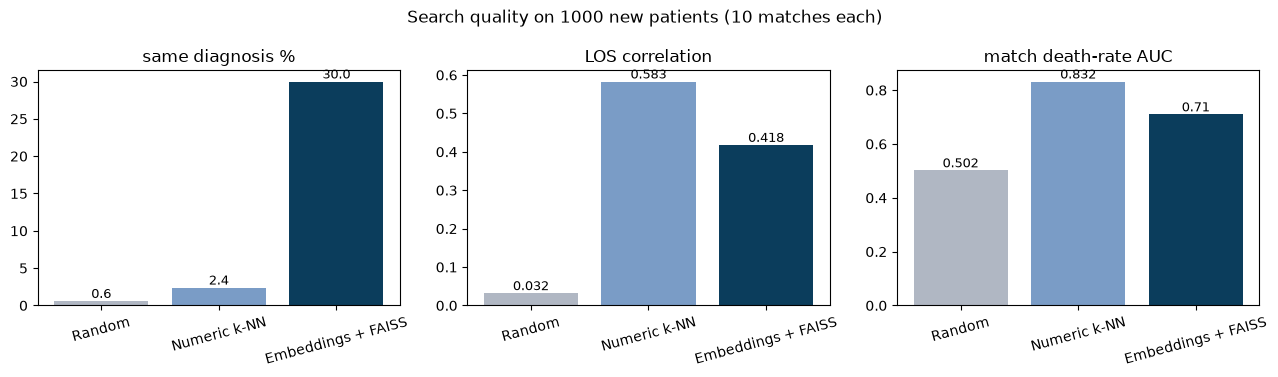

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
colors = ["#b0b7c3", "#7a9cc6", "#0b3d5c"]

for ax, col in zip(axes, ["same diagnosis %", "LOS correlation", "match death-rate AUC"]):
    ax.bar(results.index, results[col], color=colors)
    ax.set_title(col)
    ax.tick_params(axis="x", labelrotation=15)
    for i, value in enumerate(results[col]):
        ax.text(i, value, str(value), ha="center", va="bottom", fontsize=9)

plt.suptitle(f"Search quality on {len(new_patients)} new patients (10 matches each)")
plt.tight_layout()
plt.savefig("images/retrieval_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Observation
- **Both methods are much better than random.** Random matches give an AUC of 0.50 (a coin flip) and only 0.6% same diagnosis.
- **Embeddings are best at finding the same diagnosis:** 30% of matches have exactly the same diagnosis, against 2.4% for numeric k-NN. The numeric method cannot read the diagnosis text, and that is the main gain from using text.
- **Numeric k-NN is stronger on the measured outcome-related comparisons:** better length-of-stay correlation (0.58 vs 0.42), much smaller age gap (6.3 vs 15.8 years) and higher AUC (0.83 vs 0.71).
- **Why:** numeric k-NN uses the exact age and activity counts, and the activity counts may reflect care intensity across the stay (they were also top features in the mortality model). The embeddings see age only as a number in the text and the counts only as low / medium / high, so most of that detail is lost.
- **Conclusion:** embeddings are not automatically better. They capture **what the patient came in for**; numeric features retain **age and care-activity detail**. A real system should use both, for example by keeping only embedding matches in the same age range.

## 9. Failure Analysis

Two checks on the embedding search:
1. **How close is the best match?** If even the best match has low similarity, the library has nobody really like this patient.
2. **Missed deaths:** patients who died, but all 10 of their matches survived. Here the similar-patient view would look falsely reassuring.

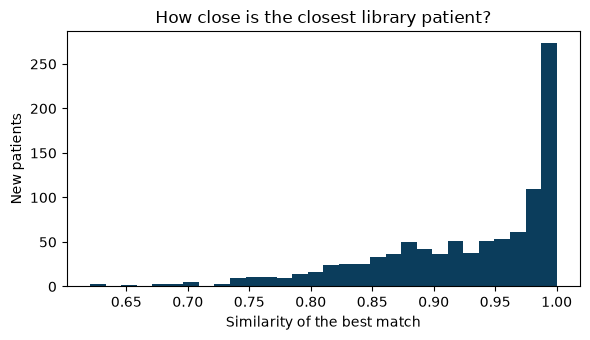

Median best-match similarity: 0.948
Patients whose best match is below 0.80: 78


In [23]:
best_score = scores[:, 0]    # similarity of the best match for each new patient

plt.figure(figsize=(6, 3.5))
plt.hist(best_score, bins=30, color="#0b3d5c")
plt.xlabel("Similarity of the best match")
plt.ylabel("New patients")
plt.title("How close is the closest library patient?")
plt.tight_layout()
plt.show()

print("Median best-match similarity:", round(float(np.median(best_score)), 3))
print("Patients whose best match is below 0.80:", int((best_score < 0.80).sum()))

In [24]:
embedding_table = match_table(neighbor_ids)

missed = new_patients[(embedding_table["died"] == 1) & (embedding_table["match_death_rate"] == 0)]

print("Patients who died:", int(new_patients["ExpiredHospital"].sum()))
print("...of whom all 10 matches survived:", len(missed))

missed[["age", "admit_type", "AdmitDiagnosis", "AdmitProcedure"]].head(8)

Patients who died: 114
...of whom all 10 matches survived: 19


,age,admit_type,AdmitDiagnosis,AdmitProcedure
16,52,EMERGENCY,C5 FRACTURE;S/P FALL,Skin closure NEC
26,85,EMERGENCY,HYPOTENSION,Insert endotracheal tube
141,88,EMERGENCY,INFECTED GRAFT,Vasc proc revision NEC
143,63,EMERGENCY,SUBARACHNOID HEMORRHAGE,Cont inv mec ven <96 hrs
144,57,EMERGENCY,GASTROINTESTINAL BLEED/THROMBOCYTOPENIA,Oth endo proc oth vessel
159,35,EMERGENCY,ABDOMINAL PAIN,Other brain dx procedure
237,77,EMERGENCY,RESP FAILURE-RENAL FAILURE-CONGESTIVE HEART FAILURE,Ven cath renal dialysis
249,87,EMERGENCY,ACUTE RENAL FAILURE,na


### Observation
- The median best-match similarity is **0.948**, so most new patients have a very close match. 78 of 1,000 (7.8%) have no match above 0.80; these have unusual diagnoses that a library of 4,000 patients does not cover well.
- **19 of the 114 patients who died (16.7%)** had 10 matches who all survived. Their diagnoses, such as hypotension, brain bleed (subarachnoid hemorrhage), GI bleed and a fall with a neck fracture, are common and usually survived. What made these cases fatal is not in the summary.
- This is the main risk of this approach: it shows what **usually** happened to similar patients, not what will happen to this one. It is a reference tool, not a risk score.

## 10. Retrieval-Augmented Generation with Llama 3.1

The search finds the similar patients; the LLM writes a short comparison of them. This is **RAG (retrieval-augmented generation)**: first *retrieve* the relevant records, then let the LLM *generate* an answer using only those records.

**Why Llama 3.1 through Ollama?** Llama 3.1 8B runs on this laptop through Ollama. MIMIC patient records may not be sent to online AI services, so ChatGPT or similar services were not an option.

**Why JSON?** The LLM returns three facts as separate fields (how many matches died, their average length of stay, the most common diagnosis) plus a short explanation. Separate fields make each fact easy to check in Section 11.

Ollama must be running. Answers are saved to `outputs/rag_explanations.csv`; when that file exists, the LLM step is skipped and the saved answers are used.

In [25]:
# Check that Ollama is running
try:
    ollama.list()
    OLLAMA_READY = True
    print("Ollama is running.")
except Exception as error:
    OLLAMA_READY = False
    print("Ollama is not reachable:", error)

Ollama is running.


In [26]:
PROMPT = """You are helping a data scientist review similar past ICU admissions.
Use ONLY the records below. Do not add facts, do not give medical advice,
and do not predict the outcome of the new patient.

NEW PATIENT:
{new_summary}

SIMILAR PAST PATIENTS:
{context}

Return JSON with exactly these keys:
"similar_died": how many of the {k} similar patients died in hospital (integer),
"average_length_of_stay": their average length of stay in days (one decimal),
"most_common_diagnosis": the admitting diagnosis that appears most often among them,
"explanation": two or three sentences on what the new patient and the similar patients have in common."""


def build_context(match_rows):
    # One line of text for each matched library patient
    lines = []
    for rank, lib_row in enumerate(match_rows, start=1):
        row = library.iloc[lib_row]
        outcome = "died in hospital" if row["ExpiredHospital"] == 1 else "survived"
        lines.append(
            f"{rank}. {row['summary']} Outcome: {outcome}. "
            f"Length of stay: {row['LOSdays']:.1f} days."
        )
    return "\n".join(lines)


# Show the full prompt for the first new patient
print(PROMPT.format(
    new_summary=new_patients.loc[0, "summary"],
    context=build_context(neighbor_ids[0, :K_RAG]),
    k=K_RAG,
))

You are helping a data scientist review similar past ICU admissions.
Use ONLY the records below. Do not add facts, do not give medical advice,
and do not predict the outcome of the new patient.

NEW PATIENT:
75-year-old male. Emergency admission as a transfer from another hospital. Admitting diagnosis: endocarditis. First recorded procedure: dx ultrasound-heart. Daily care activity: high lab tests, high medications, high microbiology tests, high procedures, high charted observations.

SIMILAR PAST PATIENTS:
1. 62-year-old female. Emergency admission by clinic referral. Admitting diagnosis: endocarditis. First recorded procedure: exc/des hrt les,endovasc. Daily care activity: low lab tests, low medications, high microbiology tests, low procedures, low charted observations. Outcome: survived. Length of stay: 23.8 days.
2. 79-year-old male. Emergency admission as a transfer from another hospital. Admitting diagnosis: endocarditis. First recorded procedure: venous cath nec. Daily care acti

In [27]:
def ask_llm(prompt):
    # Send one prompt to the local model and return its text answer
    response = ollama.chat(
        model=LLM_MODEL,
        messages=[{"role": "user", "content": prompt}],
        format="json",                 # answer must be JSON
        options={"temperature": 0},    # same question -> same answer
    )
    return response["message"]["content"]


REQUIRED_KEYS = ["similar_died", "average_length_of_stay", "most_common_diagnosis", "explanation"]


def read_answer(raw_text):
    # Turn the LLM's text into a dictionary, or mark it as a failed answer
    try:
        answer = json.loads(raw_text)
    except json.JSONDecodeError:
        return {"status": "invalid JSON"}

    if not isinstance(answer, dict) or any(key not in answer for key in REQUIRED_KEYS):
        return {"status": "missing keys"}

    answer["status"] = "ok"
    return answer

In [28]:
# Pick 10 new patients: 5 who died and 5 who survived
died_rows = new_patients[new_patients["ExpiredHospital"] == 1].sample(N_RAG_PATIENTS // 2, random_state=RANDOM_STATE)
survived_rows = new_patients[new_patients["ExpiredHospital"] == 0].sample(N_RAG_PATIENTS // 2, random_state=RANDOM_STATE)
demo_patients = died_rows.index.tolist() + survived_rows.index.tolist()
print("Patients sent to the LLM:", demo_patients)

Patients sent to the LLM: [673, 26, 303, 553, 87, 50, 445, 798, 729, 992]


In [29]:
# Reuse saved Llama answers only when the patients and prompts still match.
# Otherwise, delete the saved CSV and rerun this cell to generate new answers.
if RAG_FILE.exists():
    rag = pd.read_csv(RAG_FILE)
    if len(rag) != len(demo_patients) or sorted(rag["patient_pos"].tolist()) != sorted(demo_patients):
        raise ValueError("Saved answers belong to different patients. Delete the saved CSV and rerun.")

    for _, saved in rag.iterrows():
        patient_row = int(saved["patient_pos"])
        current_prompt = PROMPT.format(
            new_summary=new_patients.loc[patient_row, "summary"],
            context=build_context(neighbor_ids[patient_row, :K_RAG]),
            k=K_RAG,
        )
        if saved["prompt"] != current_prompt:
            raise ValueError("Saved prompt or retrieved matches changed. Delete the saved CSV and rerun.")
    print("Loaded verified saved answers:", len(rag))

elif OLLAMA_READY:
    records = []
    start = time.time()
    for i, patient_row in enumerate(demo_patients, start=1):
        prompt = PROMPT.format(
            new_summary=new_patients.loc[patient_row, "summary"],
            context=build_context(neighbor_ids[patient_row, :K_RAG]),
            k=K_RAG,
        )
        records.append({"patient_pos": patient_row, "prompt": prompt, "raw_answer": ask_llm(prompt)})
        print(f"{i}/{len(demo_patients)} done ({round(time.time() - start)} s)")

    rag = pd.DataFrame(records)
    rag.to_csv(RAG_FILE, index=False)
    print("Saved to", RAG_FILE)

else:
    print("Start the Ollama app and run this cell again.")

Loaded verified saved answers: 10


In [30]:
# Split each JSON answer into columns
answers = pd.DataFrame([read_answer(text) for text in rag["raw_answer"]])
answers = answers.reindex(columns=REQUIRED_KEYS + ["status"])   # keep the same columns even if answers failed
rag = pd.concat([rag[["patient_pos", "prompt", "raw_answer"]], answers], axis=1)

print(rag["status"].value_counts())
rag[["patient_pos", "similar_died", "average_length_of_stay", "most_common_diagnosis"]]

status
ok    10
Name: count, dtype: int64


,patient_pos,similar_died,average_length_of_stay,most_common_diagnosis
0,673,2,14.1,sepsis
1,26,0,2.3,hypotension
2,303,0,8.3,percu gastrojejunostomy
3,553,0,11.1,melena
4,87,1,12.8,pleural effusion
5,50,1,3.5,icd lead complication/ice lead extraction w/icd reimplantation /sda
6,445,0,2.1,aneurysm/sda
7,798,0,5.1,sepsis
8,729,0,6.6,aortic valve replacement
9,992,0,18.1,ischemic left leg


In [31]:
# Read two explanations in full
for _, row in rag.head(2).iterrows():
    print("NEW PATIENT:", new_patients.loc[row["patient_pos"], "summary"])
    print("LLM:", row["explanation"], "\n")

NEW PATIENT: 85-year-old female. Emergency admission from the emergency room. Admitting diagnosis: sepsis. First recorded procedure: insert endotracheal tube. Daily care activity: high lab tests, high medications, high microbiology tests, high procedures, high charted observations.
LLM: The new patient and the similar patients all had sepsis as their admitting diagnosis. They also all received high levels of lab tests, medications, microbiology tests, procedures, and charted observations. This suggests that they all had severe cases of sepsis that required intensive treatment. 

NEW PATIENT: 85-year-old female. Emergency admission from the emergency room. Admitting diagnosis: hypotension. First recorded procedure: insert endotracheal tube. Daily care activity: high lab tests, high medications, high microbiology tests, high procedures, high charted observations.
LLM: All patients were admitted to the ICU with hypotension as the admitting diagnosis. They all received high lab tests and h

### Observation
- All 10 answers were valid JSON with the four required fields. Asking for JSON with fixed field names made the answers easy to read with code.
- The explanations read well and point out the obvious common features (same diagnosis, same first procedure, how intensive the care was).
- But they often **overstate**. The first explanation says all matches had "high levels of lab tests, medications, microbiology tests, procedures, and charted observations", but one of them had medium lab tests and low medications. Section 11 checks this properly.

## 11. Hallucination Check

An LLM can write fluent text that is not supported by what it was given. This is called a **hallucination**. Python can check selected facts against the retrieved records; clinical claims still require reading the explanation:

| Check | Correct when |
|---|---|
| Deaths | The LLM's count equals the true number of deaths among the 5 matches |
| Average length of stay | Within 0.5 days of the true average |
| Most common diagnosis | Matches the most frequent diagnosis (any of them if tied) |
| Numbers in the explanation | Flags numbers that do not appear in the prompt or calculated answers; this is not a complete hallucination test |

The check is built in four small steps.

**Step 1 – Work out the correct answers** from the 5 matched patients.

In [32]:
def true_facts(patient_row):
    # The correct answers, computed directly from the 5 matched patients
    matches = library.iloc[neighbor_ids[patient_row, :K_RAG]]
    dx_counts = matches["AdmitDiagnosis"].str.upper().value_counts()
    return {
        "died": int(matches["ExpiredHospital"].sum()),
        "avg_los": float(round(matches["LOSdays"].round(1).mean(), 1)),
        "top_dx": dx_counts[dx_counts == dx_counts.max()].index.tolist(),   # all tied top diagnoses
    }


# Example: correct answers for the first patient sent to the LLM
true_facts(rag.loc[0, "patient_pos"])

{'died': 2, 'avg_los': 16.1, 'top_dx': ['SEPSIS']}

**Step 2 – Helpers to read numbers from text.** `re.findall` finds every number in a piece of text.

In [33]:
def first_number(value):
    # "8.6 days" -> 8.6 ; returns None if there is no number
    found = re.findall(r"\d+(?:\.\d+)?", str(value))
    return float(found[0]) if found else None


def all_numbers(text):
    # "72-year-old, 3.5 days" -> {72.0, 3.5}
    return {float(n) for n in re.findall(r"\d+(?:\.\d+)?", str(text))}


# Examples
print(first_number("8.6 days"))
print(all_numbers("A 72-year-old stayed 3.5 days"))

8.6
{72.0, 3.5}


**Step 3 – Compare one LLM answer with the correct answers.**

In [34]:
def check_answer(row):
    facts = true_facts(row["patient_pos"])

    # 1. Read the three facts from the LLM answer
    llm_died = first_number(row["similar_died"])
    llm_los = first_number(row["average_length_of_stay"])
    llm_dx = str(row["most_common_diagnosis"]).upper().strip()

    # 2. Compare each fact with the correct answer
    died_ok = llm_died == facts["died"]
    los_ok = llm_los is not None and abs(llm_los - facts["avg_los"]) <= 0.5
    dx_ok = llm_dx in facts["top_dx"]

    # 3. Numbers in the explanation that appear neither in the prompt nor in the correct answers
    allowed = all_numbers(row["prompt"]) | {facts["died"], facts["avg_los"]}
    unsupported = all_numbers(row["explanation"]) - allowed

    return {
        "patient_pos": row["patient_pos"],
        "died: LLM": llm_died,
        "died: true": facts["died"],
        "died correct": died_ok,
        "LOS: LLM": llm_los,
        "LOS: true": facts["avg_los"],
        "LOS correct": los_ok,
        "diagnosis correct": dx_ok,
        "unsupported numbers": sorted(unsupported),
        "no invented numbers": len(unsupported) == 0,
    }

**Step 4 – Check all valid answers and count the results.**

In [35]:
valid = rag[rag["status"] == "ok"]
checks = pd.DataFrame([check_answer(row) for _, row in valid.iterrows()])
checks

,patient_pos,died: LLM,died: true,died correct,LOS: LLM,LOS: true,LOS correct,diagnosis correct,unsupported numbers,no invented numbers
0,673,2.0,2,True,14.1,16.1,False,True,[],True
1,26,0.0,0,True,2.3,2.5,True,True,[],True
2,303,0.0,0,True,8.3,8.8,True,False,[],True
3,553,0.0,0,True,11.1,11.7,False,True,[],True
4,87,1.0,1,True,12.8,11.8,False,True,[],True
5,50,1.0,1,True,3.5,3.4,True,False,[],True
6,445,0.0,0,True,2.1,2.2,True,True,[],True
7,798,0.0,0,True,5.1,4.9,True,True,[],True
8,729,0.0,0,True,6.6,7.1,True,False,[],True
9,992,0.0,0,True,18.1,16.9,False,True,[],True


In [36]:
n = len(checks)
summary = pd.Series({
    "Valid JSON answers": f"{n} / {len(rag)}",
    "Deaths counted correctly": f"{checks['died correct'].sum()} / {n}",
    "Average stay correct (within 0.5 days)": f"{checks['LOS correct'].sum()} / {n}",
    "Most common diagnosis correct": f"{checks['diagnosis correct'].sum()} / {n}",
    "Explanations with no invented numbers": f"{checks['no invented numbers'].sum()} / {n}",
}, name="result")

summary.to_frame()

,result
Valid JSON answers,10 / 10
Deaths counted correctly,10 / 10
Average stay correct (within 0.5 days),6 / 10
Most common diagnosis correct,7 / 10
Explanations with no invented numbers,10 / 10


### Observation

**Automatic checks**
- **Counting was always right:** the number of deaths was correct in 10 of 10 answers.
- **Calculating was weak:** the average length of stay was within 0.5 days in only 6 of 10. The wrong ones were off by 0.6 to 2.0 days (for example 14.1 instead of 16.1). LLMs predict words; they do not really calculate.
- **Most common diagnosis: 7 of 10.** One answer gave a procedure name (*percu gastrojejunostomy*) instead of a diagnosis. In the other two, all five diagnoses were different; the model gave a general phrase ("aortic valve replacement") or changed a `\` to a `/`, which the strict text match counts as wrong.
- **No additional numbers flagged:** the number check passed 10 of 10 explanations. This does not establish that every clinical statement was supported.

**Reading the explanations by hand**

The number check passed every answer. But reading the ten explanations next to their records shows that **each one had at least one claim the records do not support**, usually "all patients…" when only some did:

| Patient | What the LLM wrote | What the records show |
|---|---|---|
| 553 | "all had a diagnosis of melena… all underwent a partial gastrectomy" | 2 of 5 had melena; 3 of 5 had the gastrectomy |
| 992 | "all patients were admitted… for a vascular-related condition" | Includes urinary infection, abdominal pain and edema |
| 729 | "all performed using a minimally invasive approach with a heart port" | Only 1 of 5 mentions a heart port |
| 798 | "a venous catheter necrosis procedure" | `venous cath nec` means *venous catheter, not elsewhere classified* |
| 87 | "most… were elderly females, which may be a contributing factor to their similar outcomes" | A guess; the prompt said not to add facts |

**Conclusion:** in this 10-case sample, the LLM counted deaths correctly more often than it calculated averages. Checking only the numbers is not enough; the real problems were overgeneralising ("all") and misreading abbreviations. A safer design is to let Python calculate every number and use the LLM only to describe them, with rules such as "say *3 of 5*, not *all*".

## 12. Results Summary

| Area | Result |
|---|---|
| Patients | 50,740 adults; 5,000 sampled (4,000 library, 1,000 new) |
| Embeddings | 384 numbers per patient from `all-MiniLM-L6-v2`, about 3 minutes on a laptop |
| Search speed | 1,000 searches against 4,000 patients in about 0.2 seconds |
| Same diagnosis in matches | **30.0%** embeddings vs 2.4% numeric k-NN vs 0.6% random |
| Match death-rate AUC | 0.71 embeddings vs **0.83** numeric k-NN vs 0.50 random |
| Length-of-stay correlation | 0.42 embeddings vs **0.58** numeric k-NN vs 0.03 random |
| Missed deaths | 19 of 114 deaths had no death among their 10 matches |
| LLM answers | 10/10 valid JSON; deaths 10/10; average stay 6/10; diagnosis 7/10 |
| Explanation review | No additional numbers flagged (10/10); manual review found unsupported claims in all 10 |

**Main findings**
1. Embeddings let the free-text diagnosis be used in the search, which the numeric method cannot do.
2. Numeric k-NN performed better on length-of-stay correlation and match death-rate AUC. These methods preserve different patient details and may complement one another.
3. In the 10-case LLM sample, death counts were more accurate than LOS averages, and explanations sometimes overgeneralised. Python-calculated numbers are a useful next improvement.

## Limitations
- **Summaries, not doctor notes.** The text is built from columns, so it only contains what the columns contain.
- **Whole-stay activity.** The activity counts cover the full stay, so this is a look-back tool, not something to use at admission.
- **No expert check of "similar".** The search is judged with indirect measures, not by a clinician.
- **Small LLM sample.** Only 10 answers were checked; the text review was manual and not a clinician-validated assessment.
- **Strict diagnosis match.** "CHEST PAIN" and "CHEST PAIN/R/O MI" count as different, so the same-diagnosis rate is a low estimate.

## Next Steps
- Combine both methods, for example keep embedding matches within the same age range.
- Let Python calculate counts and averages and ask the LLM only to describe them.
- Add an automatic check for "all patients…" claims.
- Search all 50,740 adults and show the mortality model's risk score next to the similar patients.